# NVIDIA Kumo Tabular を Adult データで試す

2026年9月に NVIDIA が公開したテーブル基盤モデル **Kumo Tabular** を、UCI Adult (Census Income) で動かす探索ノートブック。
[01 の TabPFN-3](01_tabpfn_adult.ipynb) と同じ条件（前処理なし・無調整・同じ分割）で、学習データ量を変えたときの AUC と推論時間を比べる。

- 実行スクリプト: `experiments/02_kumo_tabular/run.py` → `results/02_kumo_tabular/sweep.json`
- 比較対象: `experiments/01_tabpfn/run.py` → `results/01_tabpfn/sweep.json`
- 図の保存先: `articles/images/`

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from tabular_sandbox.data import load_adult

# nbconvert 実行時の cwd は notebooks/ なので親をリポジトリ root とする
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "articles/images"
IMG_DIR.mkdir(parents=True, exist_ok=True)

## データを見る

カテゴリ列と欠損 (NaN) を含む生のテーブル。

In [2]:
X, y = load_adult()
print("shape:", X.shape, "| positive rate:", round(float(y.mean()), 3))
X.dtypes.astype(str).to_frame("dtype").assign(missing=X.isna().sum())

shape: (48842, 14) | positive rate: 0.239


,dtype,missing
age,int64,0
workclass,category,2799
fnlwgt,int64,0
education,category,0
education-num,int64,0
marital-status,category,0
occupation,category,2809
relationship,category,0
race,category,0
sex,category,0


## 使い方: DataFrame → TableTensor → fit / predict

TabPFN のような sklearn 互換 API ではなく、まず `sdm.TableTensor.from_pandas()` で GPU 上のテーブル型に変換する。
列の型 (stype) は `sdm.infer_stypes()` で推論でき、目的変数だけ `categorical` を明示する。

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
x_stypes = sdm.infer_stypes(X)
x_stypes

{'age': Stype.numerical,
 'workclass': Stype.categorical,
 'fnlwgt': Stype.numerical,
 'education': Stype.categorical,
 'education-num': Stype.numerical,
 'marital-status': Stype.categorical,
 'occupation': Stype.categorical,
 'relationship': Stype.categorical,
 'race': Stype.categorical,
 'sex': Stype.categorical,
 'capital-gain': Stype.numerical,
 'capital-loss': Stype.numerical,
 'hours-per-week': Stype.numerical,
 'native-country': Stype.categorical}

In [4]:
demo = X_tr.sample(1000, random_state=0)  # デモ用に1000件
demo = demo.assign(target=y_tr[X_tr.index.get_indexer(demo.index)])

train = sdm.TableTensor.from_pandas(
    df=demo, stypes=x_stypes | {"target": "categorical"}, device="cuda"
)
test = sdm.TableTensor.from_pandas(df=X_te, stypes=x_stypes, device="cuda")

model = sdm.models.KumoTabular(device="cuda")  # 初回は HF Hub から重みを取得
t0 = time.perf_counter()
model.fit(x=train.drop_columns("target"), y=train[:, "target"], num_estimators=8)
fit_sec = time.perf_counter() - t0
t0 = time.perf_counter()
pred = model.predict(test).to_pandas()
pred_sec = time.perf_counter() - t0
model.clear()
pred.head()

/opt/venv/lib/python3.12/site-packages/sdm/tensor/string.py:502: RuntimeWarning: Falling back to a CPU-based string sort because cuDF is not installed. Install cuDF to enable faster CUDA-based string sorting without device synchronization. This warning will be suppressed for the remainder of this process.
  warn_once(


/opt/venv/lib/python3.12/site-packages/sdm/relational/join.py:73: RuntimeWarning: Falling back to a CPU-based join because cuDF is not installed. Install cuDF to enable faster CUDA-based joins without device synchronization. This warning will be suppressed for the remainder of this process.
  warn_once(


,1,0
0,0.012683,0.987317
1,0.001297,0.998703
2,0.088890,0.911110
3,0.029995,0.970005
4,0.002173,0.997827


出力はクラスごとの確率で、**列名はクラスラベルの文字列・並び順は保証されない**。
同じデータ・同じ学習行でも、実行によって `['0', '1']` だったり `['1', '0']` だったりした。
sklearn の `predict_proba(...)[:, 1]` の感覚で位置で取ると、陰性クラスの確率を拾って AUC が `1 - AUC` に反転することがある。必ず列名で取る。

In [5]:
auc = roc_auc_score(y_te, pred["1"])
print("columns:", pred.columns.tolist())
print(f"train=1000  AUC={auc:.4f}  fit={fit_sec:.2f}s  predict={pred_sec:.2f}s")

columns: ['1', '0']
train=1000  AUC=0.9158  fit=1.41s  predict=4.30s


## 学習データ量を振る（AUC と推論時間）

`run.py` のスイープ結果を読み込んで可視化する。（無ければ先に `uv run python experiments/02_kumo_tabular/run.py` を実行）

In [6]:
def load_sweep(name):
    path = ROOT / f"results/{name}/sweep.json"
    return json.loads(path.read_text())


kumo = load_sweep("02_kumo_tabular")
df_kumo = pd.DataFrame(kumo["results"])
print(kumo["model"], "|", kumo["device"], "| load", f"{kumo['model_load_sec']:.1f}s")
df_kumo

NVIDIA Kumo Tabular (large) | cuda (NVIDIA GeForce RTX 5070 Ti) | load 0.6s


,n_train,auc,accuracy,fit_sec,predict_sec,peak_gpu_mem_gb,note
0,1000,0.915827,0.867335,0.599158,4.208295,2.109449,NaN
1,5000,0.926738,0.871737,4.444899,9.696805,3.372656,NaN
2,10000,0.929437,0.873170,11.042596,16.668044,4.989414,NaN
3,20000,0.932200,0.874600,31.860000,30.470000,8.200000,from previous run without warmup (same split/s...


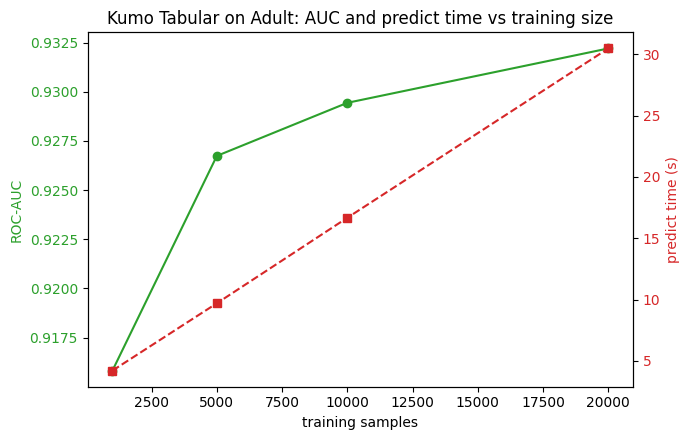

In [7]:
fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax1.plot(df_kumo["n_train"], df_kumo["auc"], "o-", color="tab:green")
ax1.set_xlabel("training samples")
ax1.set_ylabel("ROC-AUC", color="tab:green")
ax1.tick_params(axis="y", labelcolor="tab:green")
ax2 = ax1.twinx()
ax2.plot(df_kumo["n_train"], df_kumo["predict_sec"], "s--", color="tab:red")
ax2.set_ylabel("predict time (s)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")
ax1.set_title("Kumo Tabular on Adult: AUC and predict time vs training size")
fig.tight_layout()
fig.savefig(IMG_DIR / "kumo_sweep.png", dpi=130, bbox_inches="tight")
plt.show()

## TabPFN-3 と比べる

同じ分割・同じ学習サブサンプルでの比較。（無ければ先に `uv run python experiments/01_tabpfn/run.py` を実行）

In [8]:
tabpfn = load_sweep("01_tabpfn")
df_tabpfn = pd.DataFrame(tabpfn["results"])

cols = ["auc", "accuracy", "fit_sec", "predict_sec"]
comp = df_kumo.set_index("n_train")[cols].join(
    df_tabpfn.set_index("n_train")[cols],
    how="outer",
    lsuffix="_kumo",
    rsuffix="_tabpfn",
)
comp.round(4)

,auc_kumo,accuracy_kumo,fit_sec_kumo,predict_sec_kumo,auc_tabpfn,accuracy_tabpfn,fit_sec_tabpfn,predict_sec_tabpfn
n_train,,,,,,,,
1000,0.9158,0.8673,0.5992,4.2083,0.9015,0.8491,0.4446,0.7655
5000,0.9267,0.8717,4.4449,9.6968,0.9094,0.8579,0.2453,1.2882
10000,0.9294,0.8732,11.0426,16.6680,0.9132,0.8588,0.4376,2.1169
20000,0.9322,0.8746,31.8600,30.4700,0.9150,0.8598,0.3561,4.4379
39073,NaN,NaN,NaN,NaN,0.9174,0.8620,0.4928,11.3235


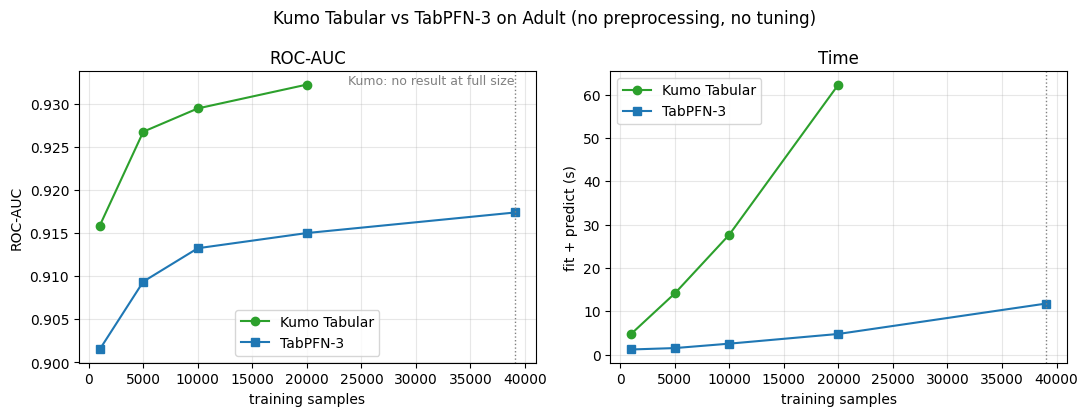

In [9]:
models = [
    ("Kumo Tabular", df_kumo, "tab:green", "o-"),
    ("TabPFN-3", df_tabpfn, "tab:blue", "s-"),
]
fig, (ax_auc, ax_time) = plt.subplots(1, 2, figsize=(11, 4.2))
for label, d, color, style in models:
    ax_auc.plot(d["n_train"], d["auc"], style, color=color, label=label)
    total = d["fit_sec"] + d["predict_sec"]
    ax_time.plot(d["n_train"], total, style, color=color, label=label)
ax_auc.set(xlabel="training samples", ylabel="ROC-AUC", title="ROC-AUC")
ax_time.set(xlabel="training samples", ylabel="fit + predict (s)", title="Time")
# Kumo の全量は手元の環境で途中終了し、結果を得られず
n_full = int(df_tabpfn["n_train"].max())
for ax in (ax_auc, ax_time):
    ax.axvline(n_full, color="gray", ls=":", lw=1)
ax_auc.annotate(
    "Kumo: no result at full size",
    xy=(n_full, df_kumo["auc"].max()),
    ha="right",
    fontsize=9,
    color="gray",
)
for ax in (ax_auc, ax_time):
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Kumo Tabular vs TabPFN-3 on Adult (no preprocessing, no tuning)")
fig.tight_layout()
fig.savefig(IMG_DIR / "kumo_vs_tabpfn.png", dpi=130, bbox_inches="tight")
plt.show()

## 所見

（スイープ結果を見てから書く）